# Analysis: NOAA Bluesky accounts, January to November 2026

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

for path in ["local_data/clean/posts_clean.csv", "data/sample_posts_clean.csv"]:
    if os.path.exists(path):
        posts = pd.read_csv(path)
        print("loaded", path)
        break
else:
    raise FileNotFoundError("posts_clean.csv not found. Run collect_data.py and clean_data.py first.")

os.makedirs("figures", exist_ok=True)
posts["created_local"] = pd.to_datetime(posts["created_local"])
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

print(len(posts), "posts")
posts.groupby("handle").size().rename("posts")

loaded local_data/clean/posts_clean.csv
836 posts


handle
noaacomms.noaa.gov     56
nws.noaa.gov          780
Name: posts, dtype: int64

## Posts per month

In [2]:
per_month = posts.pivot_table(index="month", columns="handle", values="uri", aggfunc="count", fill_value=0)
per_month

handle,noaacomms.noaa.gov,nws.noaa.gov
month,,
2025-12,0,1
2026-01,2,81
2026-02,4,47
2026-03,12,98
2026-04,3,68
2026-05,5,80
2026-06,9,81
2026-07,3,71
2026-08,6,50


## Posts by weekday

In [3]:
by_weekday = posts.pivot_table(index="weekday", columns="handle", values="uri", aggfunc="count", fill_value=0).reindex(days, fill_value=0)
by_weekday

handle,noaacomms.noaa.gov,nws.noaa.gov
weekday,,
Monday,7,140
Tuesday,8,124
Wednesday,14,116
Thursday,20,133
Friday,7,180
Saturday,0,28
Sunday,0,59


## Posts by hour of day (Eastern time)

In [4]:
by_hour = posts.pivot_table(index="hour", columns="handle", values="uri", aggfunc="count", fill_value=0).reindex(range(24), fill_value=0)
share_by_hour = by_hour / by_hour.sum()
share_by_hour.round(3)

handle,noaacomms.noaa.gov,nws.noaa.gov
hour,,
0,0.000,0.000
1,0.000,0.000
2,0.000,0.000
3,0.000,0.000
4,0.000,0.000
5,0.000,0.001
6,0.000,0.013
7,0.000,0.060
8,0.000,0.026


## Media use and reposts

In [5]:
summary = posts.groupby("handle").agg(
    posts=("uri", "count"),
    share_image_or_video=("has_media", "mean"),
    median_likes=("likes", "median"),
    median_reposts=("reposts", "median"),
)
summary.round(3)

,posts,share_image_or_video,median_likes,median_reposts
handle,,,,
noaacomms.noaa.gov,56,0.143,7.0,2.0
nws.noaa.gov,780,0.958,81.5,20.0


## Figures

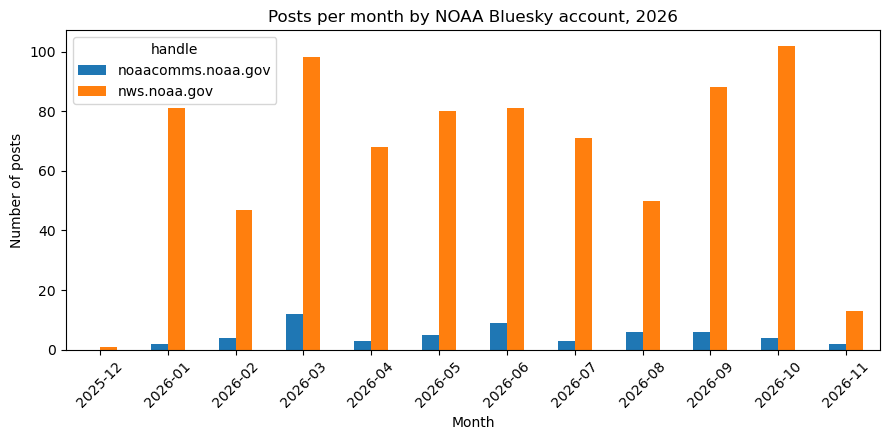

In [6]:
ax = per_month.plot.bar(figsize=(9, 4.5), rot=45)
ax.set_title("Posts per month by NOAA Bluesky account, 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Number of posts")
plt.tight_layout()
plt.savefig("figures/posts_per_month.png", dpi=150)
plt.show()

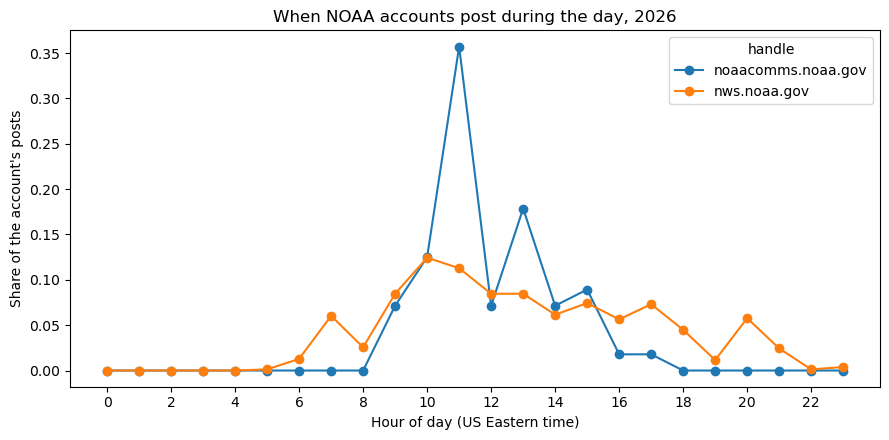

In [7]:
ax = share_by_hour.plot(figsize=(9, 4.5), marker="o")
ax.set_title("When NOAA accounts post during the day, 2026")
ax.set_xlabel("Hour of day (US Eastern time)")
ax.set_ylabel("Share of the account's posts")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig("figures/posts_by_hour.png", dpi=150)
plt.show()

## Findings text for the README

In [8]:
handles = list(summary.index)
last_date = posts["created_local"].max().strftime("%B %d, %Y").replace(" 0", " ")

lines = []
counts = ", ".join(f"{h} posted {summary.loc[h, 'posts']} times" for h in handles)
lines.append(f"Between January 1 and {last_date}, {counts}. climate.noaa.gov had no posts in this period, so the comparison is between the accounts above.")
lines.append("")
for h in handles:
    top_day = by_weekday[h].idxmax()
    top_hour = by_hour[h].idxmax()
    lines.append(
        f"- **{h}**: most posts on {top_day}s, busiest hour {top_hour}:00 Eastern, "
        f"{summary.loc[h, 'share_image_or_video']:.0%} of posts have an image or video, "
        f"median {summary.loc[h, 'median_reposts']:.0f} reposts and {summary.loc[h, 'median_likes']:.0f} likes per post."
    )
lines.append("")
lines.append("These results are descriptive and preliminary. Counts of likes and reposts are a snapshot from the collection date, and the data cannot show why one account posts differently from another.")
lines.append("")
lines.append("![Posts per month](figures/posts_per_month.png)")
lines.append("")
lines.append("*Figure 1. Number of posts per month for each NOAA account that posted in 2026.*")
lines.append("")
lines.append("![Posts by hour](figures/posts_by_hour.png)")
lines.append("")
lines.append("*Figure 2. Share of each account's posts made in each hour of the day, in US Eastern time.*")

print("\n".join(lines))

Between January 1 and November 8, 2026, noaacomms.noaa.gov posted 56 times, nws.noaa.gov posted 780 times. climate.noaa.gov had no posts in this period, so the comparison is between the accounts above.

- **noaacomms.noaa.gov**: most posts on Thursdays, busiest hour 11:00 Eastern, 14% of posts have an image or video, median 2 reposts and 7 likes per post.
- **nws.noaa.gov**: most posts on Fridays, busiest hour 10:00 Eastern, 96% of posts have an image or video, median 20 reposts and 82 likes per post.

These results are descriptive and preliminary. Counts of likes and reposts are a snapshot from the collection date, and the data cannot show why one account posts differently from another.

![Posts per month](figures/posts_per_month.png)

*Figure 1. Number of posts per month for each NOAA account that posted in 2026.*

![Posts by hour](figures/posts_by_hour.png)

*Figure 2. Share of each account's posts made in each hour of the day, in US Eastern time.*
